In [1]:
#libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

Combined_Datasets_EDA = pd.read_csv('Final_cleanedDataset.csv')


Combined_Datasets_EDA.head()
len(Combined_Datasets_EDA)

FileNotFoundError: [Errno 2] No such file or directory: 'Final_cleanedDataset.csv'

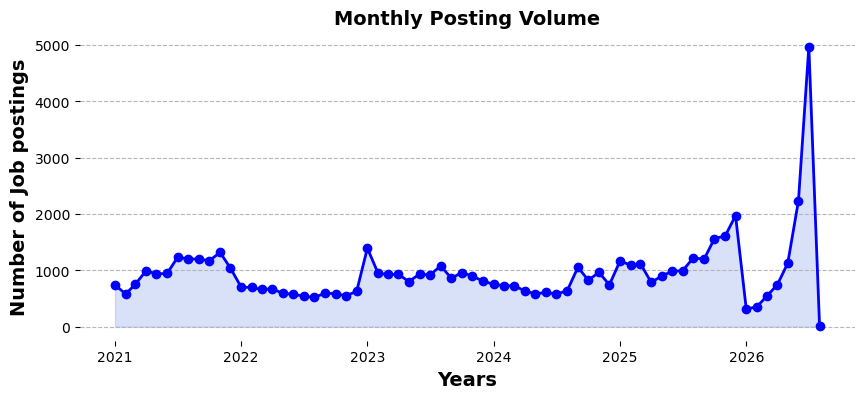

In [11]:
#hiring volume months

# Calendar date
Combined_Datasets_EDA['Posting_date'] = pd.to_datetime(
    Combined_Datasets_EDA['Posting_date'], 
    errors='coerce'
)

# Filter out anything before 2021 and any missing dates
valid_df = Combined_Datasets_EDA[
    (Combined_Datasets_EDA['Posting_date'] >= '2021-01-01') & 
    (Combined_Datasets_EDA['Posting_date'].notna())
].copy()

#  monthly period
valid_df['year_month'] = valid_df['Posting_date'].dt.to_period('M').dt.to_timestamp()

# Group and plot(sorting and counting)
monthly_counts = valid_df.groupby('year_month').size()
#monthly_counts.plot(kind='line')


#Plot
plt.figure(figsize=(10, 4))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", color="blue", linewidth=2)
plt.fill_between(monthly_counts.index, monthly_counts.values, color="royalblue", alpha=0.2)

# add titles and remove clutter
plt.title("Monthly Posting Volume", fontsize=14, weight="bold")
plt.xlabel('Years', fontsize=14, weight="bold")
plt.ylabel('Number of Job postings', fontsize=14, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.9)
plt.box(False)  # removing surrounding border box

plt.show()

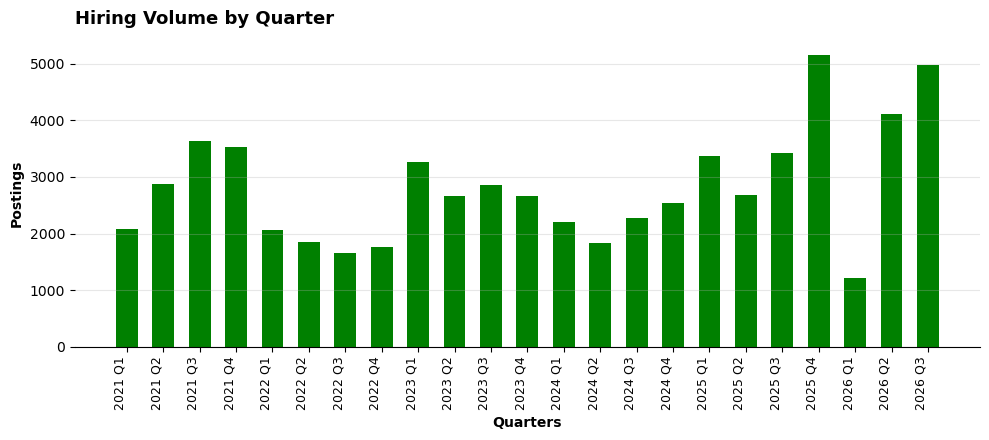

In [12]:
#Quarterly anaylsis


# Filter out anything before 2021 and any missing dates
valid_df = Combined_Datasets_EDA[
    (Combined_Datasets_EDA['Posting_date'] >= '2021-01-01') & 
    (Combined_Datasets_EDA['Posting_date'].notna())
].copy()

Combined_Datasets_EDA['Posting_date'] = pd.to_datetime(
    Combined_Datasets_EDA['Posting_date'], 
    errors='coerce'
)



# Group by quarter('2021Q1', '2021Q2')
#quarterly_counts = Combined_Datasets_EDA.groupby(
#    Combined_Datasets_EDA['Posting_date'].dt.to_period('Q')
#).size()

quarter_label = (
    Combined_Datasets_EDA['Posting_date'].dt.year.astype(str) 
    + ' Q' 
    + Combined_Datasets_EDA['Posting_date'].dt.quarter.astype(str)
)

quarterly_counts = Combined_Datasets_EDA.groupby(quarter_label).size()


# Plot
plt.figure(figsize=(10, 4.5))
bars = plt.bar(
    quarterly_counts.index.astype(str),
    quarterly_counts.values,
    color="green",
    width=0.6,
    edgecolor="none"
)

# Style & Title
plt.title("Hiring Volume by Quarter", fontsize=13, weight="bold", loc="left", pad=12)
plt.ylabel("Postings", fontsize=10, weight="bold", color="black")
plt.xlabel('Quarters', fontsize=10, weight="bold", color="black")
plt.xticks(rotation=90, ha="right", fontsize=9)


plt.grid(axis="y", alpha=0.3)
sns.despine(left=True)
plt.tight_layout()
plt.show()

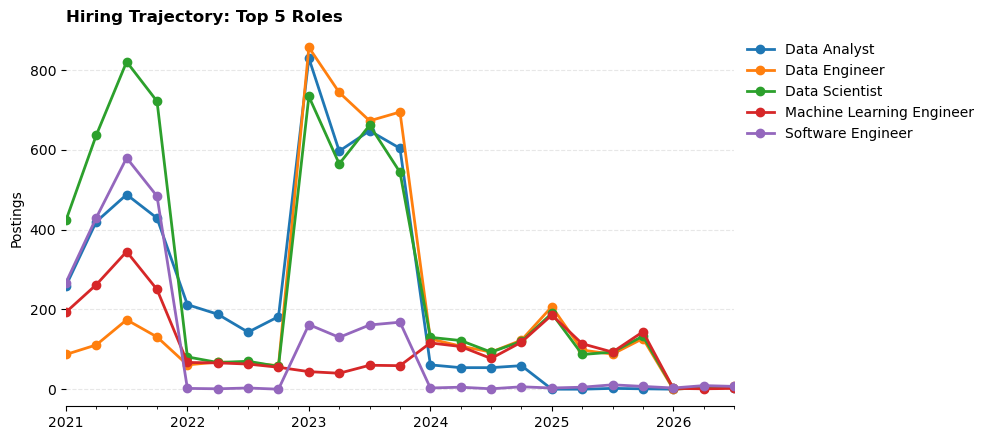

In [13]:
#Hiring for the top 5 jobs

#the top 5 roles
top_5 = Combined_Datasets_EDA['Job_Title'].value_counts().head(5).index

#quarterly counts per role
role_counts = (
    Combined_Datasets_EDA[Combined_Datasets_EDA['Job_Title'].isin(top_5)]
    .groupby([Combined_Datasets_EDA['Posting_date'].dt.to_period('Q'), 'Job_Title'])
    .size()
    .unstack(fill_value=0)
)

#Plot
h_t = role_counts.plot(figsize=(10, 4.5), marker="o", linewidth=2)

plt.title("Hiring Trajectory: Top 5 Roles", fontsize=12, weight="bold", loc="left")
plt.ylabel("Postings")
plt.xlabel("")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left")

# Remove borders
plt.grid(axis="y", alpha=0.3)
sns.despine(left=True)

plt.tight_layout()
plt.show()

<Figure size 1000x450 with 0 Axes>

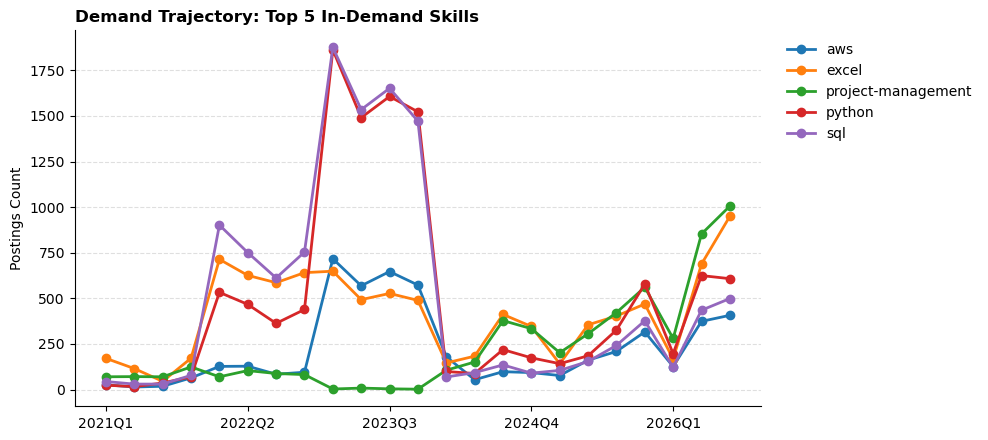

In [14]:
import matplotlib.pyplot as plt

#Clean and split skills if stored as comma-separated text
df_skills = Combined_Datasets_EDA[['Posting_date', 'Skills']].dropna().copy()
df_skills['Quarter'] = df_skills['Posting_date'].dt.to_period('Q').astype(str)

# Place skills into individual rows
df_skills['Skill_Individual'] = (
    df_skills['Skills']
    .astype(str)
    .str.replace(r"[\[\]']", "", regex=True)
    .str.split(r',\s*')
)

#converts from a list into multiple rows
df_exploded = df_skills.explode('Skill_Individual')
df_exploded['Skill_Individual'] = df_exploded['Skill_Individual'].str.strip()

# Filter out empty strings
df_exploded = df_exploded[df_exploded['Skill_Individual'] != '']

# Top 5 skills overall
top_5_skills = df_exploded['Skill_Individual'].value_counts().head(5).index

# Top 5 Skills as columns
skill_trends = (
    df_exploded[df_exploded['Skill_Individual'].isin(top_5_skills)]
    .groupby(['Quarter', 'Skill_Individual'])
    .size()
    .unstack(fill_value=0)
)

#Plot
plt.figure(figsize=(10, 4.5))
ax = skill_trends.plot(figsize=(10, 4.5), marker="o", linewidth=2)

plt.title("Demand Trajectory: Top 5 In-Demand Skills", fontsize=12, weight="bold", loc="left")
plt.ylabel("Postings Count")
plt.xlabel("")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

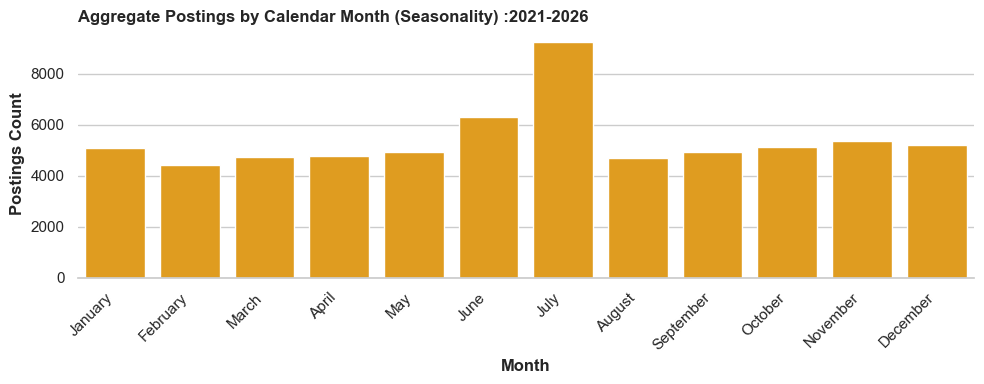

In [15]:
#checking monthly postings on average

sns.set_theme(style="whitegrid")

#Extract calendar month
Combined_Datasets_EDA['month_name'] = Combined_Datasets_EDA['Posting_date'].dt.month_name()
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]

#plot
plt.figure(figsize=(10, 4))
sns.countplot(data=Combined_Datasets_EDA, x='month_name', order=month_order, color="orange")

plt.title("Aggregate Postings by Calendar Month (Seasonality) :2021-2026", weight="bold", loc="left")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Month",weight="bold")
plt.ylabel("Postings Count",weight="bold")
sns.despine(left=True)

plt.tight_layout()
plt.show()

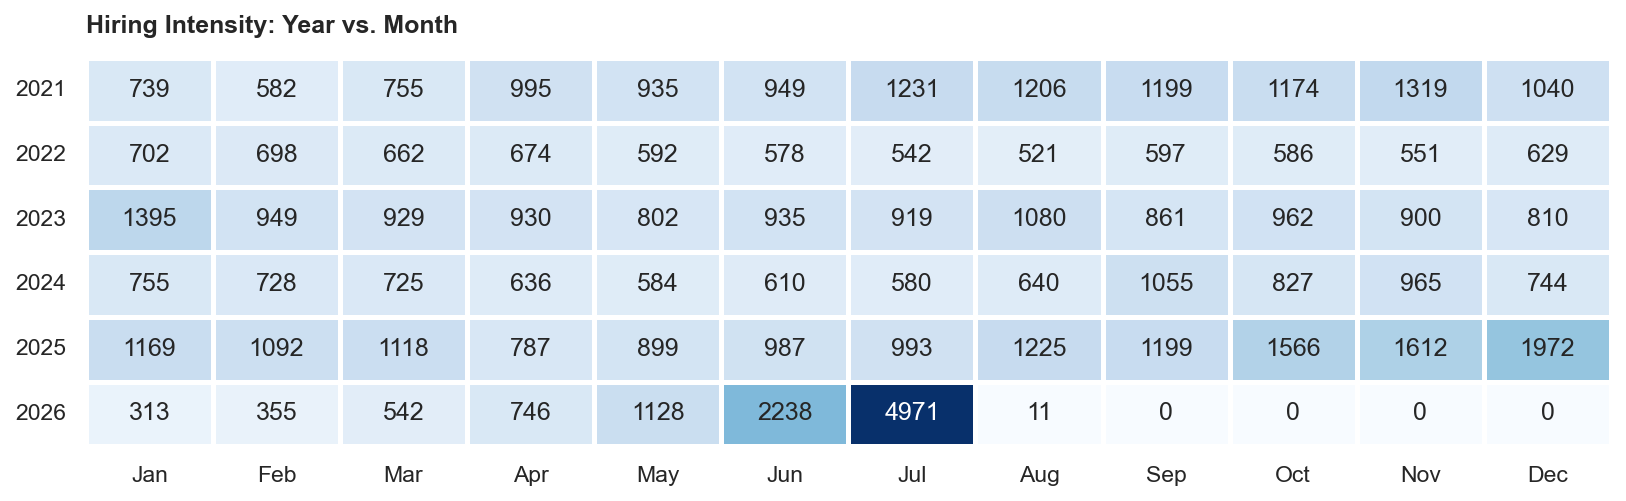

In [16]:
#heatmap of postings

# Prepare Year & Month columns
df_valid = Combined_Datasets_EDA[Combined_Datasets_EDA['Posting_date'] >= '2021-01-01'].copy()
df_valid['Year'] = df_valid['Posting_date'].dt.year
df_valid['Month'] = df_valid['Posting_date'].dt.month

# 2D matrix (Years x Months)
heatmap_data = df_valid.pivot_table(
    index='Year', 
    columns='Month', 
    aggfunc='size', 
    fill_value=0
)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
heatmap_data.columns = [month_labels[m - 1] for m in heatmap_data.columns]

#Plot heatmap with numbers inside each cell
plt.figure(figsize=(11, 3.5), dpi=150)
sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    linewidths=1.5, 
    linecolor="white",
    cbar=False
)

plt.title("Hiring Intensity: Year vs. Month", fontsize=12, weight="bold", loc="left", pad=12)
plt.xlabel("")
plt.ylabel("")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [17]:
#map
import plotly.express as px
import re

country_map = {
    'US': 'United States',
    'USA': 'United States',
    'UK': 'United Kingdom',
    'MX': 'Mexico',
    'ZA': 'South Africa',
    'FI': 'Finland',
    'NO': 'Norway',
    'HK': 'Hong Kong',
    'PR': 'Puerto Rico',
    'VI': 'U.S. Virgin Islands',
    'Czechia': 'Czech Republic',
    'Macedonia (FYROM)': 'North Macedonia'
}

US_STATES = {'Missouri', 'Kansas', 'California', 'Oklahoma', 'Arkansas', 'Texas'}

def clean_country(val):
    if not isinstance(val, str):
        return None
    val = val.strip()
    
    
    if val in ['Anywhere', '', 'nan']:
        return None
    

    if val.startswith('United States'):
        return 'United States'
    

    if re.search(r',\s*[A-Z]{2}$', val):
        return 'United States'
    

    if val in US_STATES or val.endswith(' County, KS'):
        return 'United States'

    return country_map.get(val, val)


Combined_Datasets_EDA['clean_country'] = Combined_Datasets_EDA['Country'].apply(clean_country)

country_counts = (
    Combined_Datasets_EDA['clean_country']
    .dropna()
    .value_counts()
    .reset_index()
)
country_counts.columns = ['Country', 'Postings']
unique_countries = Combined_Datasets_EDA['Country'].unique()
print(unique_countries)

['Canada' 'USA' 'Germany' 'Singapore' 'UK' 'Australia' 'India' 'Russia'
 'Spain' 'United States of America' 'Egypt' 'Romania' 'Ukraine' 'Turkey'
 'Uganda' 'Brazil' 'France' 'Bangladesh' 'Nigeria' 'South Korea'
 'Pakistan' 'China' 'Colombia' 'Viet Nam' 'Philippines' 'Greece' 'Mexico'
 'Ethiopia' 'Iran, Islamic Republic of...' 'Netherlands' 'Japan'
 'Thailand' 'Italy' 'Algeria' 'Czech Republic' 'Taiwan' 'Kenya'
 'Indonesia' 'Portugal'
 'United Kingdom of Great Britain and Northern Ireland' 'Switzerland'
 'South Africa' 'Sri Lanka' 'Ireland' 'Malaysia' 'Tunisia' 'Chile'
 'Poland' 'Norway' 'Ghana' 'Belarus' 'Iraq' 'Argentina' 'Peru' 'Morocco'
 'Sweden' 'Denmark' 'Nepal' 'Israel' 'Saudi Arabia' 'Ecuador' 'Belgium'
 'I do not wish to disclose my location' 'Hong Kong (S.A.R.)'
 'United Arab Emirates' 'Austria' 'Kazakhstan' 'United States'
 'United Kingdom' 'Hungary' 'Vietnam' 'Costa Rica' 'Bulgaria' 'Czechia'
 'Hong Kong' 'Lithuania' 'Serbia' 'Estonia' 'New Zealand' 'Finland'
 'Slovenia' 'Uru

In [18]:
#main_map
import plotly.express as px

#gemini

# 1. Map country names to ISO-3 codes
iso3_map = {
    'United States': 'USA', 'Canada': 'CAN', 'Germany': 'DEU', 'United Kingdom': 'GBR',
    'Australia': 'AUS', 'India': 'IND', 'Singapore': 'SGP', 'Mexico': 'MEX',
    'South Africa': 'ZAF', 'Finland': 'FIN', 'Norway': 'NOR', 'Hong Kong': 'HKG',
    'Puerto Rico': 'PRI', 'United States Virgin Islands': 'VIR', 'Romania': 'ROU',
    'Belgium': 'BEL', 'Turkey': 'TUR', 'Kenya': 'KEN', 'Hungary': 'HUN',
    'Vietnam': 'VNM', 'China': 'CHN', 'Japan': 'JPN', 'Ukraine': 'UKR',
    'Indonesia': 'IDN', 'Poland': 'POL', 'Portugal': 'PRT', 'Israel': 'ISR',
    'Netherlands': 'NLD', 'Egypt': 'EGY', 'France': 'FRA', 'Nigeria': 'NGA',
    'Costa Rica': 'CRI', 'Philippines': 'PHL', 'Argentina': 'ARG', 'Bulgaria': 'BGR',
    'Italy': 'ITA', 'Brazil': 'BRA', 'Czech Republic': 'CZE', 'Taiwan': 'TWN',
    'United Arab Emirates': 'ARE', 'Spain': 'ESP', 'Colombia': 'COL', 'Thailand': 'THA',
    'Bangladesh': 'BGD', 'Ireland': 'IRL', 'Pakistan': 'PAK', 'Malaysia': 'MYS',
    'Sweden': 'SWE', 'Saudi Arabia': 'SAU', 'Morocco': 'MAR', 'Lithuania': 'LTU',
    'Serbia': 'SRB', 'Denmark': 'DNK', 'South Korea': 'KOR', 'Switzerland': 'CHE',
    'Austria': 'AUT', 'Estonia': 'EST', 'New Zealand': 'NZL', 'Greece': 'GRC',
    'Peru': 'PER', 'Slovenia': 'SVN', 'Uruguay': 'URY', 'Latvia': 'LVA',
    'Chile': 'CHL', 'Croatia': 'HRV', 'Ghana': 'GHA', 'Slovakia': 'SVK',
    'Sudan': 'SDN', 'Luxembourg': 'LUX', 'Uzbekistan': 'UZB', 'Guatemala': 'GTM',
    'Jordan': 'JOR', 'Cyprus': 'CYP', 'Qatar': 'QAT', 'Bahrain': 'BHR',
    'Uganda': 'UGA', 'Kyrgyzstan': 'KGZ', 'Malta': 'MLT', 'North Macedonia': 'MKD',
    'Lebanon': 'LBN', 'Jamaica': 'JAM', 'Russia': 'RUS', 'Belarus': 'BLR',
    'Sri Lanka': 'LKA', 'Honduras': 'HND', 'Tunisia': 'TUN', 'Dominican Republic': 'DOM',
    'El Salvador': 'SLV', 'Kuwait': 'KWT', 'Nicaragua': 'NIC', 'Ecuador': 'ECU',
    'Moldova': 'MDA', 'Mauritius': 'MUS', 'Panama': 'PAN', 'Kazakhstan': 'KAZ',
    'Armenia': 'ARM', 'Iraq': 'IRQ', 'Namibia': 'NAM', 'Guam': 'GUM',
    'Nepal': 'NPL', 'Zimbabwe': 'ZWE', 'Trinidad and Tobago': 'TTO', 'Montenegro': 'MNE',
    'Suriname': 'SUR', 'Oman': 'OMN', 'Algeria': 'DZA', 'Albania': 'ALB',
    'Mongolia': 'MNG', 'Cambodia': 'KHM', 'Ivory Coast': 'CIV'
}

# 2. Add ISO-3 column to your aggregated dataset
country_counts['iso_alpha'] = country_counts['Country'].map(iso3_map)
alias_map = {
    'US': 'United States',
    'USA': 'United States',
    'UK': 'United Kingdom',
    'MX': 'Mexico',
    'ZA': 'South Africa',
    'FI': 'Finland',
    'NO': 'Norway',
    'HK': 'Hong Kong',
    'PR': 'Puerto Rico',
    'VI': 'United States Virgin Islands',
    'U.S. Virgin Islands': 'United States Virgin Islands',
    'Czechia': 'Czech Republic',
    'Macedonia (FYROM)': 'North Macedonia',
    "Côte d'Ivoire": "Ivory Coast"
}

# Standalone US states and counties present in your array
us_places = {'Missouri', 'Kansas', 'Shawnee County, KS'}

def clean_country(val):
    if not isinstance(val, str):
        return None
    val = val.strip()

    # Drop non-location placeholders
    if val in ['Anywhere', 'nan', '']:
        return None

    # Handle all "City, ST" entries
    if ',' in val and not val.startswith('United States'):
       
        suffix = val.split(',')[-1].strip()
        if len(suffix) == 2 and suffix.isupper():  
            return 'United States'

    # Handle multi-location US strings like "United States (+9 others)"
    if val.startswith('United States'):
        return 'United States'

    # Handle standalone state/county names
    if val in us_places:
        return 'United States'

    # Return standardized name or default
    return alias_map.get(val, val)

Combined_Datasets_EDA['clean_country'] = Combined_Datasets_EDA['Country'].apply(clean_country)

# 3. Check clean list (every US city/state is now gone)
print(sorted(Combined_Datasets_EDA['clean_country'].dropna().unique()))

Combined_Datasets_EDA.to_csv('Combined_Datasets_EDA.csv')

['Albania', 'Algeria', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Brazil', 'Bulgaria', 'Cambodia', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Finland', 'France', 'Germany', 'Ghana', 'Greece', 'Guam', 'Guatemala', 'Honduras', 'Hong Kong', 'Hong Kong (S.A.R.)', 'Hungary', 'I do not wish to disclose my location', 'India', 'Indonesia', 'Iran, Islamic Republic of...', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Namibia', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Peru', 'Philippines', 'Poland', 'Po

C:\Users\27769\AppData\Local\Temp\ipykernel_21684\3266006767.py:11: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


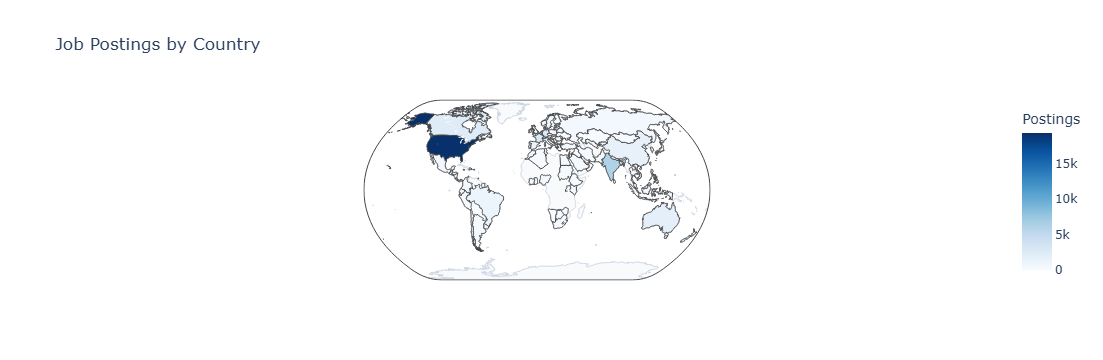

In [19]:
# Aggregate counts
country_counts = (
    Combined_Datasets_EDA['clean_country']
    .dropna()
    .value_counts()
    .reset_index()
)
country_counts.columns = ['Country', 'Postings']

# Plotly choropleth
fig = px.choropleth(
    country_counts,
    locations='Country',
    locationmode='country names',
    color='Postings',
    color_continuous_scale='Blues',
    title='Job Postings by Country',
    template='plotly_white'
)

fig.update_geos(
    showcoastlines=True,
    coastlinecolor="#cbd5e1",
    showland=True,
    landcolor="#f8fafc",
    projection_type="natural earth"
)

fig.show()

C:\Users\27769\AppData\Local\Temp\ipykernel_21684\3326827284.py:1: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



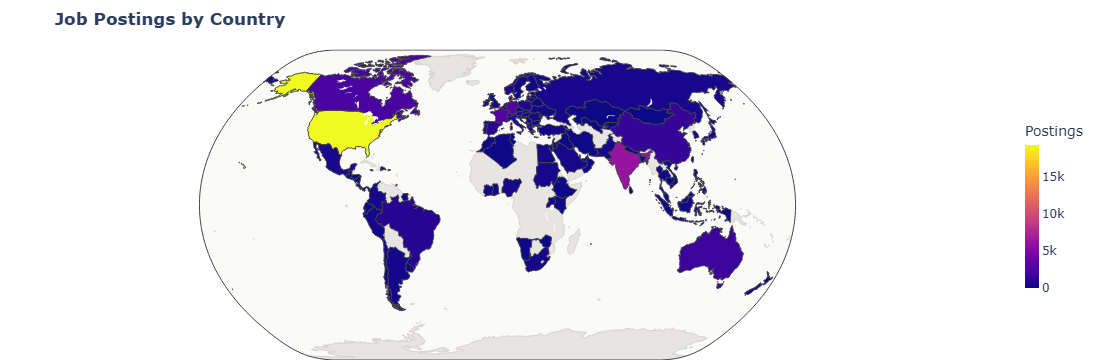

In [20]:
fig = px.choropleth(
    country_counts,
    locations='Country',
    locationmode='country names',
    color='Postings',
    color_continuous_scale="Plasma", # Deep navy, Magenta,Warm Orange, Gold
    title='<b>Job Postings by Country</b>',
    template='plotly_white'
)

fig.update_geos(
    showocean=True,
    oceancolor="#fafaf9", # Warm color
    showland=True,
    landcolor="#e7e5e4", #gray for 0 data countries
    showcoastlines=True,
    coastlinecolor="#d6d3d1",
    projection_type="natural earth"
)

fig.update_layout(
    margin=dict(l=0, r=0, t=50, b=0),
    coloraxis_colorbar=dict(
        title="Postings",
        thickness=14,
        len=0.6
    )
)

fig.show()

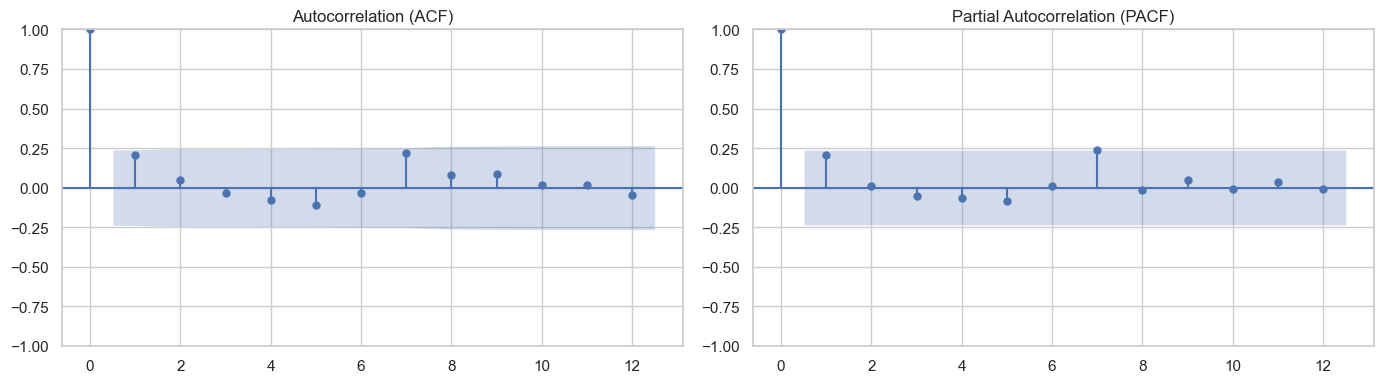

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


# Convert to datetime and create 'year_month'
Combined_Datasets_EDA['Posting_date'] = pd.to_datetime(Combined_Datasets_EDA['Posting_date'])
Combined_Datasets_EDA['year_month'] = Combined_Datasets_EDA['Posting_date'].dt.to_period('M').dt.to_timestamp()

#Aggregate total monthly postings into ts_data
ts_data = (
    Combined_Datasets_EDA
    .groupby('year_month')
    .size()
    .reset_index(name='year')
    .rename(columns={'year_month': 'calendar'})
    .sort_values('calendar')
)



# Cap lags at half the series length so statsmodels doesn't throw a boundary error
max_lags = min(12, max(1, len(ts_data) // 2 - 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ts_data['year'].dropna(), lags=max_lags, ax=axes[0], title="Autocorrelation (ACF)")
plot_pacf(ts_data['year'].dropna(), lags=max_lags, ax=axes[1], title="Partial Autocorrelation (PACF)", method='ywm')
plt.tight_layout()
plt.show()

#print(ts_data.head())